## DEP Lab Experiment 4

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans


#### SET 1: Descriptive Statistics &amp; Data Understanding

1. importing dataset (California housing data)

In [57]:
df = pd.read_csv("Datasets/housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


2. Mean, Median, Variance, Std Deviation, Skewness and Kutosis

In [58]:
# Select only numerical features
num_df = df.select_dtypes(include=[np.number])

stats_summary = pd.DataFrame({
    'Mean': num_df.mean(),
    'Median': num_df.median(),
    'Variance': num_df.var(),
    'Standard Deviation': num_df.std(),
    'Skewness': num_df.skew(),
    'Kurtosis': num_df.kurt()
})
display(stats_summary)

,Mean,Median,Variance,Standard Deviation,Skewness,Kurtosis
longitude,-119.569704,-118.4900,4.014139e+00,2.003532,-0.297801,-1.330152
latitude,35.631861,34.2600,4.562293e+00,2.135952,0.465953,-1.117760
housing_median_age,28.639486,29.0000,1.583963e+02,12.585558,0.060331,-0.800629
total_rooms,2635.763081,2127.0000,4.759445e+06,2181.615252,4.147343,32.630927
total_bedrooms,537.870553,435.0000,1.775654e+05,421.385070,3.459546,21.985575
population,1425.476744,1166.0000,1.282470e+06,1132.462122,4.935858,73.553116
households,499.539680,409.0000,1.461760e+05,382.329753,3.410438,22.057988
median_income,3.870671,3.5348,3.609323e+00,1.899822,1.646657,4.952524
median_house_value,206855.816909,179700.0000,1.331615e+10,115395.615874,0.977763,0.327870


3. Identify: Outliters, Feature ranges & Missing Values

Outlier Detection

In [59]:
# Outlier Detection using IQR
Q1 = num_df.quantile(0.25)
Q3 = num_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((num_df < lower_bound) | (num_df > upper_bound)).sum()
print("Total Outliers in each category: \n", outliers_count)

Total Outliers in each category: 
 longitude                0
latitude                 0
housing_median_age       0
total_rooms           1287
total_bedrooms        1271
population            1196
households            1220
median_income          681
median_house_value    1071
dtype: int64


Missing Values & Feature Ranges

In [60]:
print("Missing Values: \n",df.isnull().sum(), "\n")
# print()
# print("\n")

# 2. Feature Ranges
print("Feature Ranges (Min to Max)")
ranges_df = pd.DataFrame({
    'Minimum': num_df.min(),
    'Maximum': num_df.max(),
    'Range (Max - Min)': num_df.max() - num_df.min()
})
display(ranges_df)

Missing Values: 
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64 

Feature Ranges (Min to Max)


,Minimum,Maximum,Range (Max - Min)
longitude,-124.3500,-114.3100,10.0400
latitude,32.5400,41.9500,9.4100
housing_median_age,1.0000,52.0000,51.0000
total_rooms,2.0000,39320.0000,39318.0000
total_bedrooms,1.0000,6445.0000,6444.0000
population,3.0000,35682.0000,35679.0000
households,1.0000,6082.0000,6081.0000
median_income,0.4999,15.0001,14.5002
median_house_value,14999.0000,500001.0000,485002.0000


#### SET 2: Data Distribution Analysis

1. Box Plot

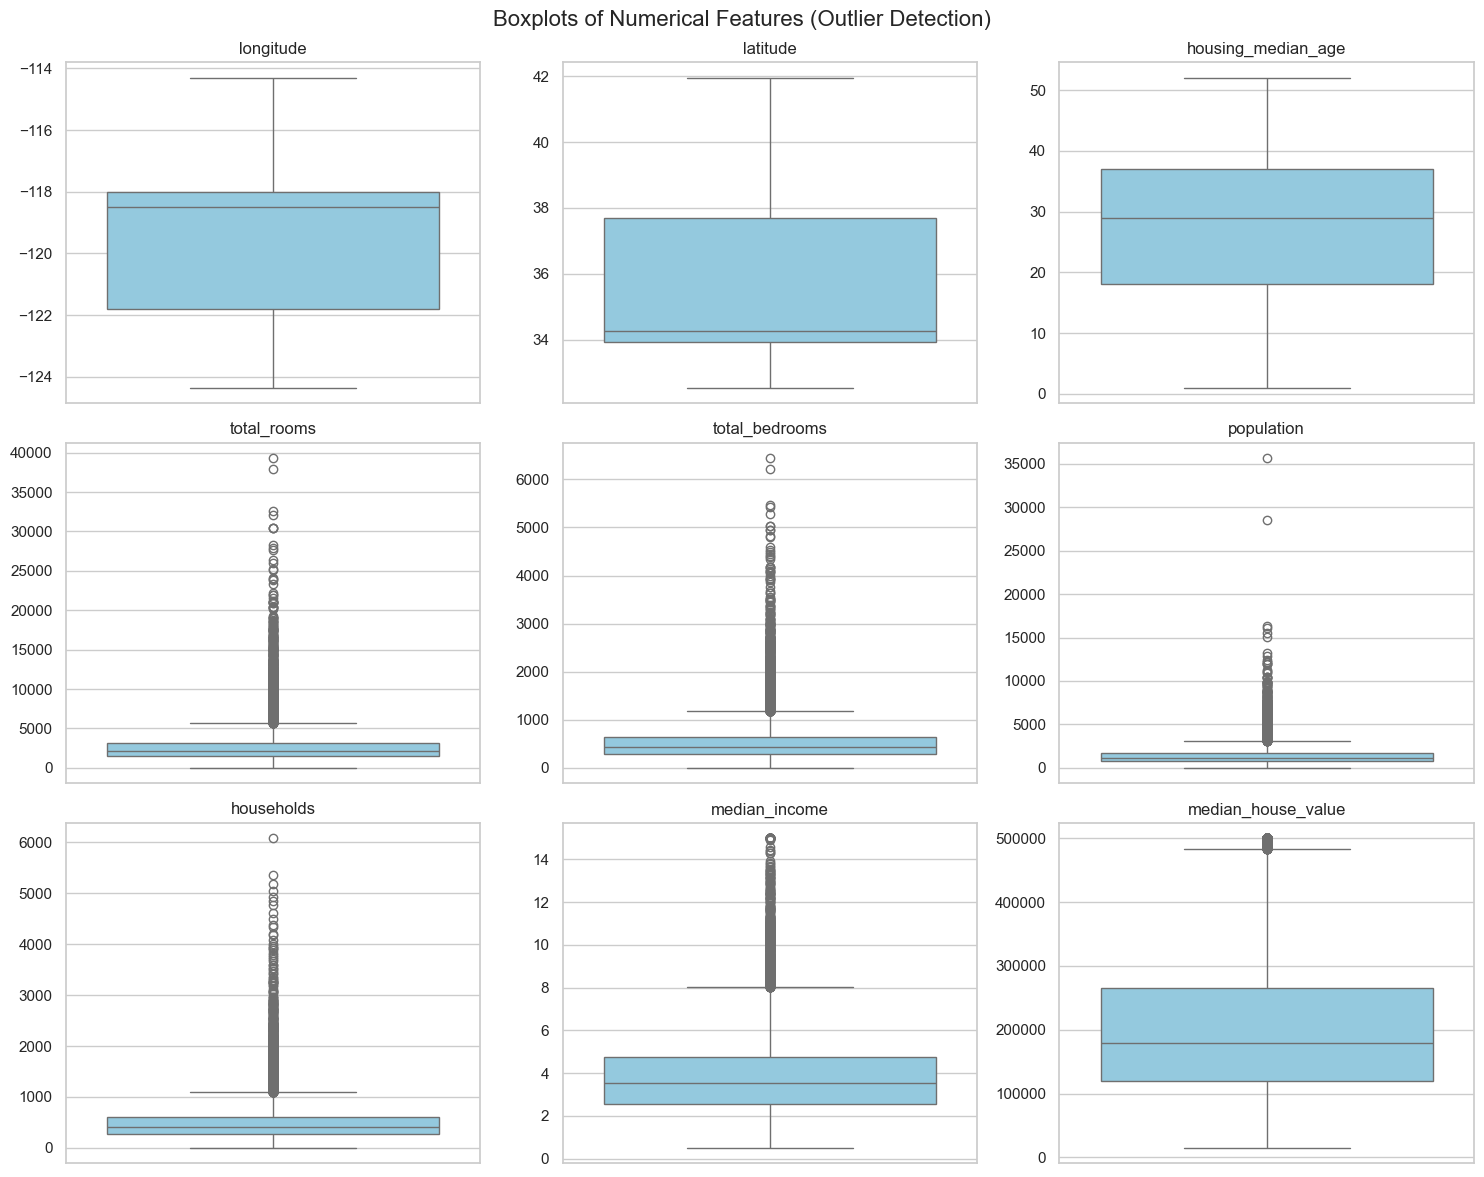

In [61]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
fig.suptitle('Boxplots of Numerical Features (Outlier Detection)', fontsize=16)
axes = axes.flatten()

for i, col in enumerate(num_df.columns): # Loop through numerical columns and plot
    sns.boxplot(y=num_df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_ylabel('')

# Remove any empty subplots if the number of features isn't exactly 9
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

2. Histograms

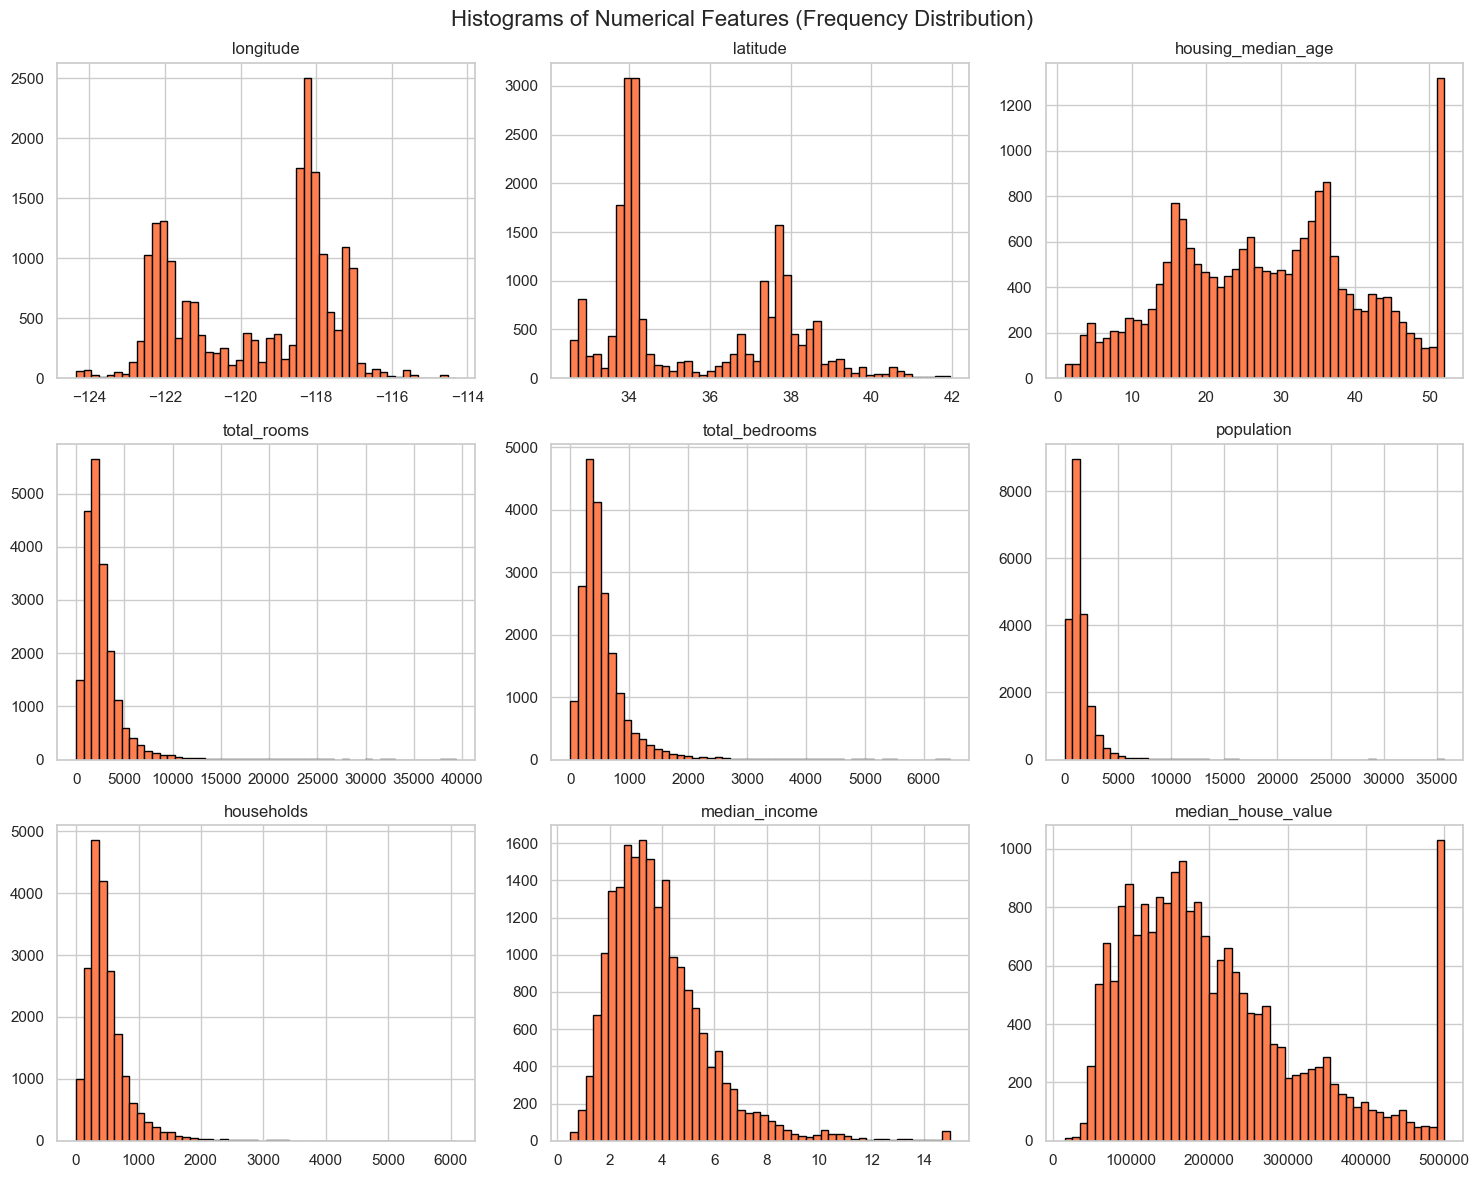

In [62]:
# bins=50; granular look
num_df.hist(bins=50, figsize=(15, 12), color='coral', edgecolor='black')

plt.suptitle('Histograms of Numerical Features (Frequency Distribution)', fontsize=16)
plt.tight_layout()
plt.show()

3. Density Curves

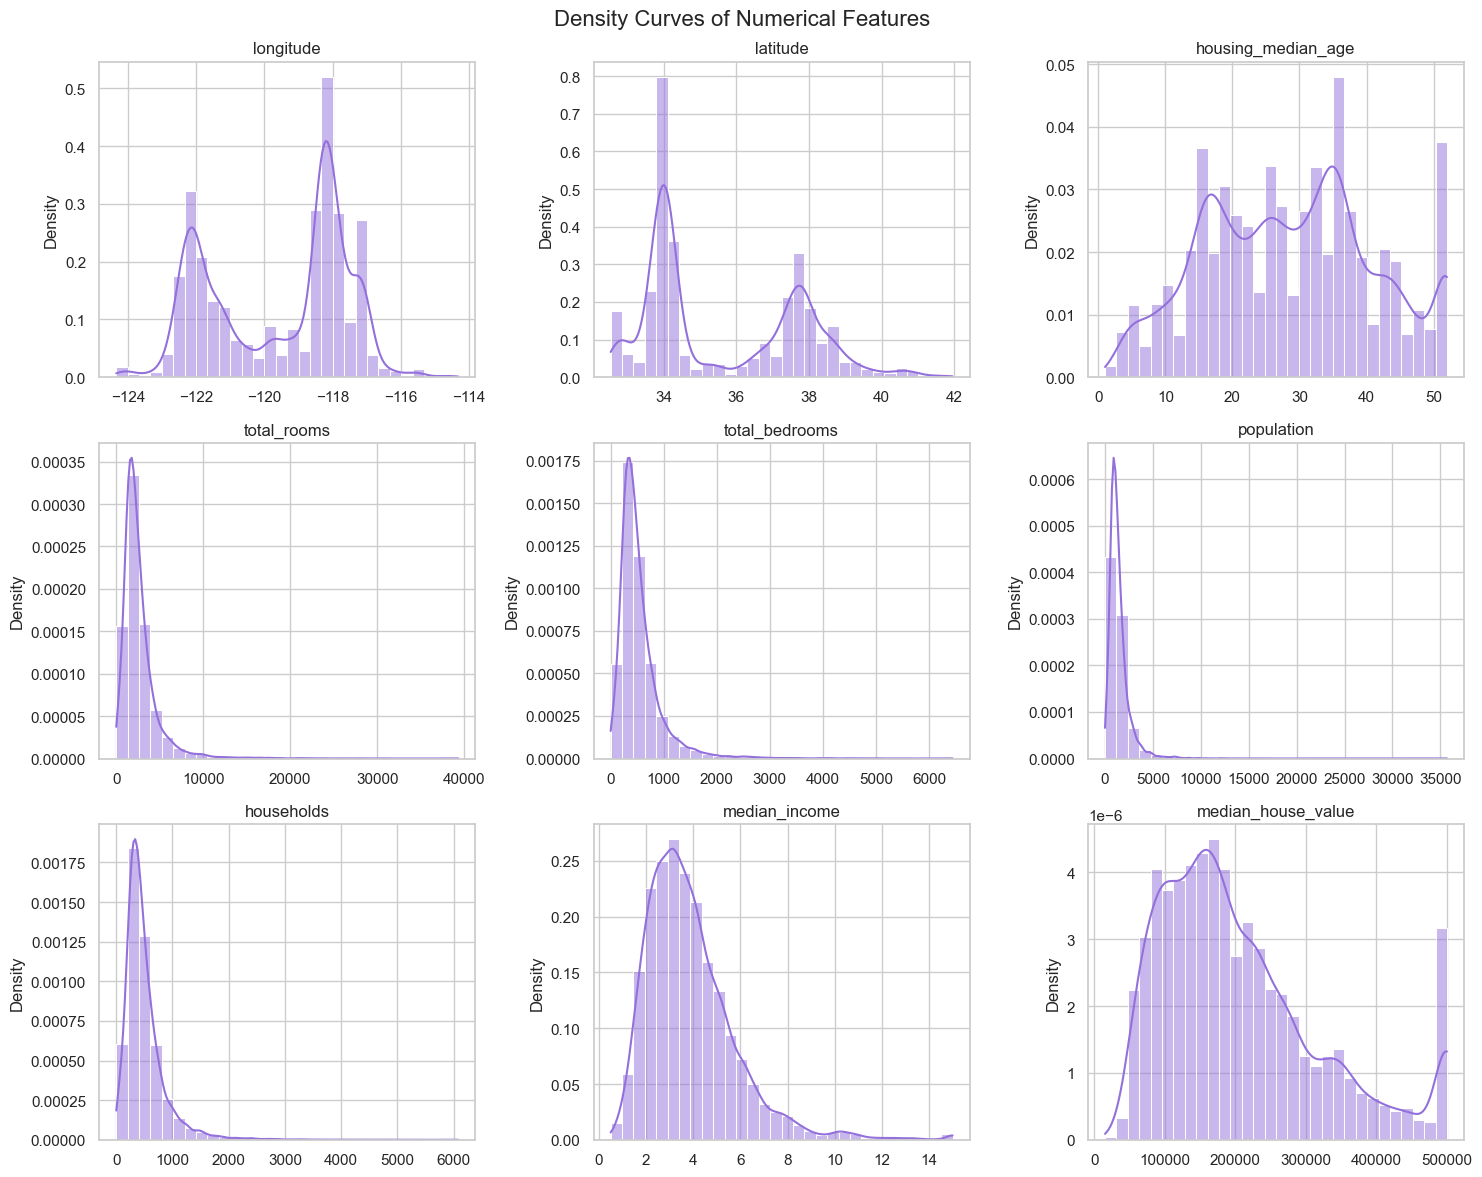

In [63]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
fig.suptitle('Density Curves of Numerical Features', fontsize=16)

axes = axes.flatten()

for i, col in enumerate(num_df.columns):
    sns.histplot(num_df[col], kde=True, ax=axes[i], color='mediumpurple', stat="density", bins=30)
    axes[i].set_title(col)
    axes[i].set_ylabel('Density')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### SET 3: Correlation Analysis

1. Correlation Matrix

In [64]:
corr_matrix = num_df.corr()
print("Correlation Matrix")
display(corr_matrix)

Correlation Matrix


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


2. Plotting Heatmap

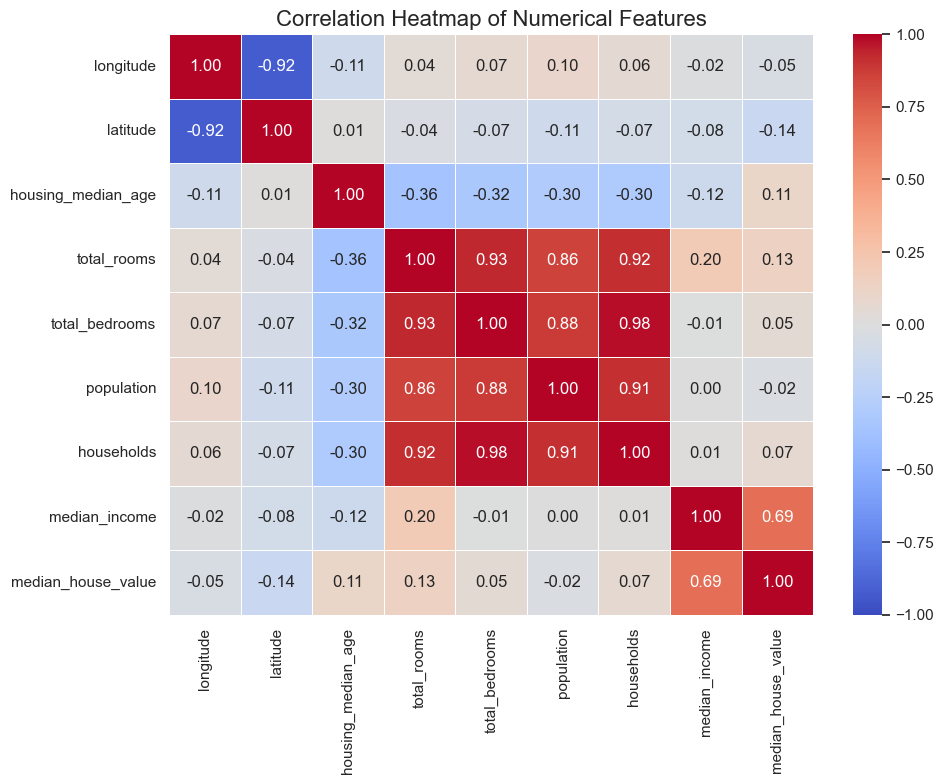

In [65]:
plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title('Correlation Heatmap of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

3. Identifying multicolinearity

In [66]:
threshold = 0.80 # Considered as high threshold

corr_pairs = corr_matrix.unstack()
high_corr_pairs = corr_pairs[(abs(corr_pairs) > threshold) & (corr_pairs != 1.0)]
high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Correlation']).reset_index()
high_corr_df.columns = ['Feature 1', 'Feature 2', 'Correlation']

#Dropping duplicates 
high_corr_df['Sorted_Pair'] = high_corr_df.apply(lambda row: tuple(sorted([row['Feature 1'], row['Feature 2']])), axis=1)
unique_high_corr = high_corr_df.drop_duplicates(subset=['Sorted_Pair']).drop(columns=['Sorted_Pair'])

print(f"Highly Correlated Feature Pairs (Threshold > {threshold})")
display(unique_high_corr.sort_values(by='Correlation', ascending=False, key=abs))

Highly Correlated Feature Pairs (Threshold > 0.8)


,Feature 1,Feature 2,Correlation
7,total_bedrooms,households,0.979728
2,total_rooms,total_bedrooms,0.930380
0,longitude,latitude,-0.924664
4,total_rooms,households,0.918484
10,population,households,0.907222
6,total_bedrooms,population,0.877747
3,total_rooms,population,0.857126


#### SET 4: Linear Regression

1. Splitting dataset into train/test

In [67]:
X = num_df.drop('median_house_value', axis=1)
y = num_df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: X={X_train.shape}, y={y_train.shape}")
print(f"Testing data shape: X={X_test.shape}, y={y_test.shape}")

Training data shape: X=(16512, 8), y=(16512,)
Testing data shape: X=(4128, 8), y=(4128,)


2. Building Linear Regression model

In [68]:
from sklearn.impute import SimpleImputer

# Impute missing values with the median before training
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_imputed, y_train)

y_pred = lr_model.predict(X_test_imputed) # Generate predictions using the trained model
print("Model training complete")

Model training complete


Evaluation Metrices: R² score, MAE, RMSE

In [69]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"MAE:      ${mae:,.2f}")
print(f"RMSE:     ${rmse:,.2f}")

R² Score: 0.6139
MAE:      $51,810.09
RMSE:     $71,131.26


#### SET 5: Principal Component Analysis (PCA)

1. Standardize data
2. Apply PCA

In [70]:
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)
# 1. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 2. Apply PCA 
pca_full = PCA()
pca_full.fit(X_scaled)
print("Data standardized and PCA fitted.")

Data standardized and PCA fitted.


3. Plot explained variance ratio

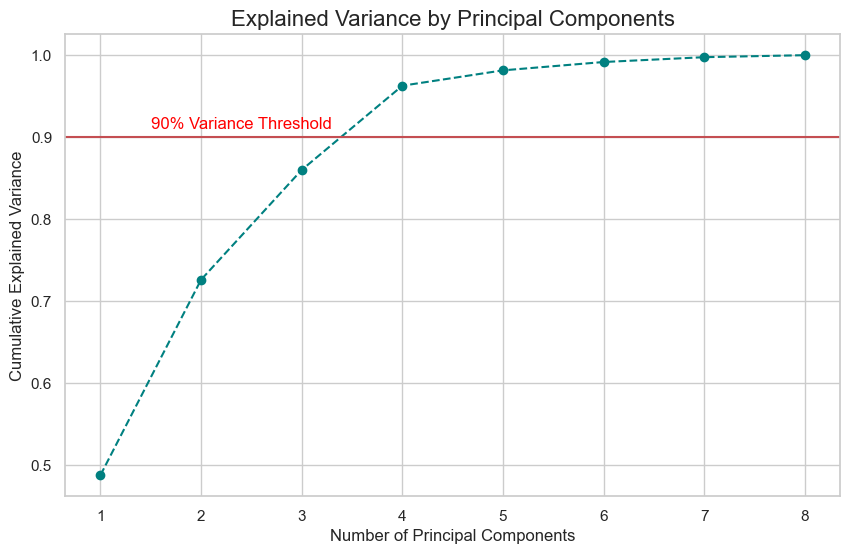

In [71]:
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Plotting the variance ratio
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='teal')
plt.axhline(y=0.90, color='r', linestyle='-')
plt.text(1.5, 0.91, '90% Variance Threshold', color = 'red', fontsize=12)

plt.title('Explained Variance by Principal Components', fontsize=16)
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.show()

4. Reduce to 2 or 3 principal components

In [72]:
# Reducign to 3 principal components
pca_3 = PCA(n_components=3)
X_pca = pca_3.fit_transform(X_scaled)

# Create a clean DataFrame 
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2', 'PC3'])

print("Explained variance ratio for 3 components:", pca_3.explained_variance_ratio_)
print(f"Total variance captured: {sum(pca_3.explained_variance_ratio_) * 100:.2f}%\n")
print(f"Original features shape: {X.shape}")
print(f"New PCA features shape: {pca_df.shape}")
display(pca_df.head())

Explained variance ratio for 3 components: [0.48755031 0.2384736  0.13397572]
Total variance captured: 86.00%

Original features shape: (20640, 8)
New PCA features shape: (20640, 3)


,PC1,PC2,PC3
0,-2.092975,1.395685,2.049315
1,2.944575,1.933398,2.150665
2,-1.969358,1.464425,1.179856
3,-1.918714,1.506095,0.383864
4,-1.776373,1.564810,-0.468629


#### SET 6: Clustering

Determining Optimal k using elbow method

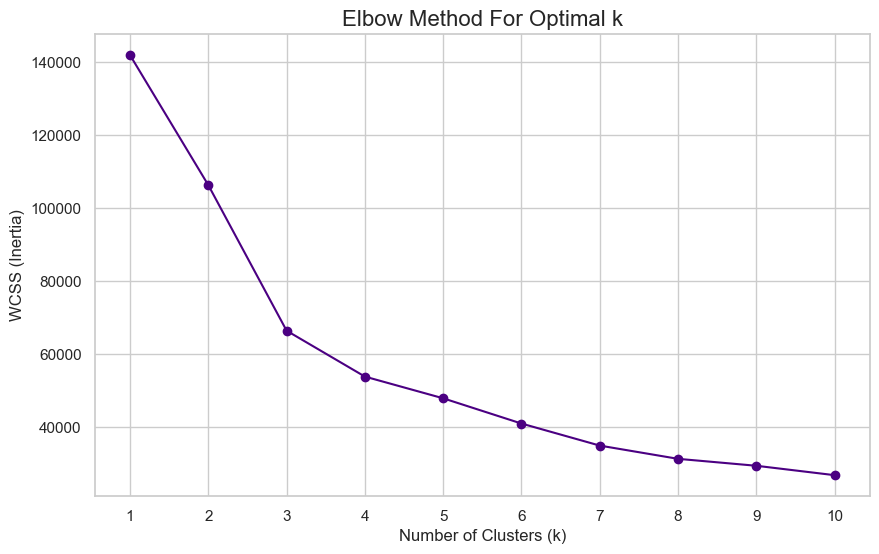

In [ ]:
wcss = []
k_range = range(1, 11)

for i in k_range:
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init='auto')
    kmeans.fit(pca_df) # Using the PCA dataframe from Set 5
    wcss.append(kmeans.inertia_)

# Plot the Elbow Graph
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, marker='o', linestyle='-', color='indigo')
plt.title('Elbow Method For Optimal k', fontsize=16)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Applying K-means and visualizing clusters

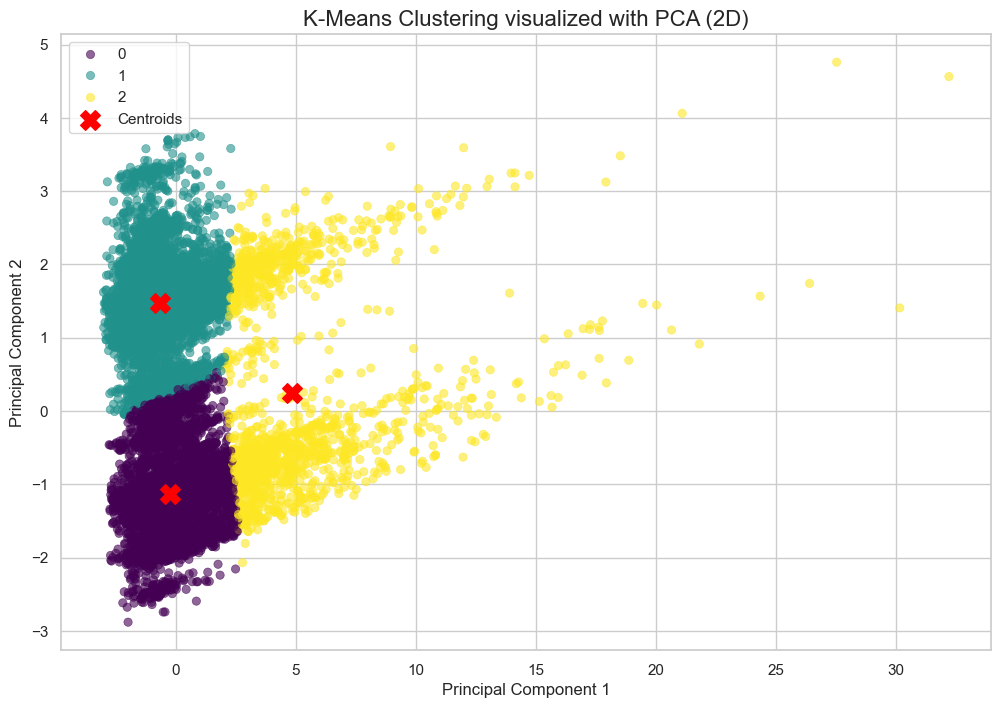

In [ ]:
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init='auto')
cluster_labels = final_kmeans.fit_predict(pca_df)
pca_df['Cluster'] = cluster_labels

# Visualize clusters using the first two PCA components (PC1 and PC2)
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Cluster', 
    palette='viridis', 
    data=pca_df, 
    alpha=0.6, 
    edgecolor=None
)

# Plot the centroids of the clusters as red 'X's
centroids = final_kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='red', marker='X', label='Centroids')

plt.title('K-Means Clustering visualized with PCA (2D)', fontsize=16)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()